In [18]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, Literal
from langchain_cohere import ChatCohere
from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv

<function dotenv.main.load_dotenv(dotenv_path: Union[str, ForwardRef('os.PathLike[str]'), NoneType] = None, stream: Optional[IO[str]] = None, verbose: bool = False, override: bool = False, interpolate: bool = True, encoding: Optional[str] = 'utf-8') -> bool>

In [19]:
model = model = ChatCohere(
    model="command-a-03-2025",
)

In [20]:
class Sentiment(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(description='sentiment of the review')

class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the reviewer')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgently this issue needs to be addressed')

In [21]:
structured_model = model.with_structured_output(Sentiment)
structured_model2 = model.with_structured_output(DiagnosisSchema)

In [22]:
class ReviewState(TypedDict):
    review: str
    sentiment: Literal['positive', 'negative']
    diagnosis: dict
    response: str

In [33]:
def generate_review(state: ReviewState) -> ReviewState:
    prompt= 'generate a random explained negative review of a product'
    review = model.invoke(prompt).content
    
    return {'review': review}

def find_sentiment(state: ReviewState) -> ReviewState:
    prompt = f'For the following review find the sentiment \n {state["review"]}'
    sentiment = structured_model.invoke(prompt).sentiment

    return {"sentiment": sentiment}

def check_sentiment(state: ReviewState) -> Literal["positive_response", "run_diagnosis"]:
    if state["sentiment"] == 'positive':
        return 'positive_response'
    else:
        return 'run_diagnosis'

def positive_response(state: ReviewState) -> ReviewState:
    prompt = f"""
    Write a warm thank you message in response to this review:
    \n\n {state['review']} \n
    Also kindly ask the user to leave feedback on our website
    """

    response = model.invoke(prompt)
    return {"response": response.content}

def run_diagnosis(state: ReviewState) -> ReviewState:
    prompt = f"""Diagnose this negative review: \n\n {state['review']} \n 
    return issue_type, tone and urgency
    """

    response = structured_model2.invoke(prompt)
    return {"diagnosis": response.model_dump()}

def negative_response(state: ReviewState) -> ReviewState:
    diagnosis = state["diagnosis"]
    prompt=f"""You are a support assistant. The user had a {diagnosis['issue_type']} issue, 
    sounded {diagnosis['tone']}, and marked urgency as {diagnosis['urgency']}
    write an empathetic, helpful resolution message 
    """

    message = model.invoke(prompt)
    return {'response': message.content}


In [34]:
graph = StateGraph(ReviewState)

graph.add_node('generate_review', generate_review)
graph.add_node('find_sentiment', find_sentiment)
graph.add_node('positive_response', positive_response)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('negative_response', negative_response)

graph.add_edge(START, 'generate_review')
graph.add_edge('generate_review', 'find_sentiment')
graph.add_conditional_edges('find_sentiment', check_sentiment)
graph.add_edge('positive_response', END)
graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)
graph.add_edge('find_sentiment', END)

workflow = graph.compile()

# initial_state = {'review': 'this product is very bad'}
workflow.invoke({})

{'review': '**Product:** SmartClean Pro Robotic Vacuum  \n\n**Rating:** ⭐ (1/5)  \n\n**Review Title:** "Overpriced, Underperforming, and Frustratingly Unreliable"  \n\n**Review:**  \nI was so excited to purchase the SmartClean Pro Robotic Vacuum after reading all the glowing reviews, but unfortunately, my experience has been nothing short of disappointing. For a device that costs over $500, I expected top-notch performance, but it fell short in almost every category.  \n\nFirst, the **navigation system** is abysmal. Instead of efficiently cleaning my open-plan living room, it constantly gets stuck under furniture, bumps into walls, and misses entire sections of the floor. I’ve had to manually rescue it multiple times, which defeats the purpose of a "smart" vacuum.  \n\nSecond, the **battery life** is a joke. It claims to run for 120 minutes, but in reality, it barely lasts 70 minutes before needing a recharge. And the worst part? It doesn’t even return to its charging dock reliably. I’

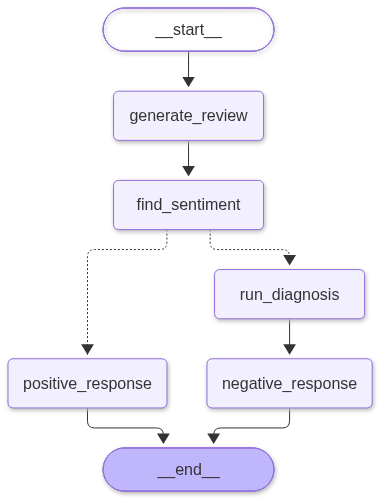

In [31]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())